## Notebook for Experimenting Summarizer Generation

Author : Bagas Noor Fadhilah  
Student Number : 18223115  
  
---  
This notebook serves as an experiment playground for finetuning a model for summarization purpose and is part of a 3 stage pipeline. This model would be on the end of the pipeline or presumably the 3rd stage. The planned metrics that are going to be used are ROUGE, NLI, and if possible BERTScore. ROUGE serves as a lexical metric that is similar to EM (Exact Matching) and NLI would be monitoring the hallucinations that could be produced by the model. The model is going to be deployed via ngrok using their endpoint and the endpoint itself is going to be use from our local laptop that runs the python CLI script for demo.
  



```
{
  "input_text": "Summarize the following Steam reviews into a concise paragraph. Adhere strictly to the target aspects and their sentiments.\n\nTarget Aspects: Content: vast (positive) | Progression: rewarding (positive) | UI: dated (negative)\n\nReviews:\n- There is an insane amount of bosses, biomes, and gear to craft.\n- Progression feels earned every time you take down hardmode bosses.\n- Inventory management and UI feel cluttered and old-school.",
  "target_text": "Players praise the vast amount of craftable content and rewarding progression system, though the inventory UI feels dated and cluttered."
}
```

In [1]:
!nvidia-smi

Wed Nov 18 06:51:26 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   47C    P8             10W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [2]:
!pip install evaluate
import evaluate

!pip install rouge_score



  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for rouge_score: filename=rouge_score-0.1.2-py3-none-any.whl size=24985 sha256=9bc0dfcd8a852c7e17e099ab31bedfffc09835c83b0622ed26a507a047bbe45a
  Stored in directory: /root/.cache/pip/wheels/44/af/da/5ffc433e2786f0b1a9c6f458d5fb8f611d8eb332387f18698f
Successfully built rouge_score


In [98]:
import gc
import os
import time
from accelerate import PartialState
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from collections import defaultdict
from datasets import Dataset, DatasetDict, load_dataset
from evaluate import load
from peft import LoraConfig, PeftModel, get_peft_model
from sentence_transformers import CrossEncoder
from sklearn.model_selection import train_test_split
from transformers import (
  AutoModelForSeq2SeqLM,
  AutoTokenizer,
  DataCollatorForSeq2Seq,
  Seq2SeqTrainer,
  Seq2SeqTrainingArguments,
  set_seed,
)


In [20]:
SEED = 42
FLAN_MODEL = "google/long-t5-tglobal-base"
BART_MODEL = "facebook/bart-base"
BART_CNN_MODEL = "facebook/bart-large-cnn"
NLI_MODEL = "cross-encoder/nli-deberta-v3-base"
set_seed(42)

In [5]:
print("CUDA available:", torch.cuda.is_available())
if torch.cuda.is_available():
  print("GPU:", torch.cuda.get_device_name(0))
  device = torch.device("cuda")
else: device = torch.device("cpu")

CUDA available: True
GPU: Tesla T4


### Initial Dataset Loading

In [7]:
df = pd.read_csv("phase3dataset.csv")
df.head()

,summary_instruction,target
0,Summarize based on Reviews: Genshin Impact's o...,Genshin Impact offers a breathtaking and deepl...
1,Summarize based on Reviews: Zenless Zone Zero ...,"Zenless Zone Zero boasts stylish animations, e..."
2,Summarize based on Reviews: Elden Ring offers ...,Elden Ring offers an immersive world discovery...
3,Summarize based on Reviews: Cyberpunk 2077's N...,Cyberpunk 2077's night city offers an exceptio...


In [8]:
# TODO: split train_df into train and validation sets

y = df['target']

X_train, X_val, y_train, y_val = train_test_split(df, y, test_size=0.2, random_state=42)

### Utility Functions

In [9]:
NLI_model = CrossEncoder(NLI_MODEL)
FLAN_tokenizer = AutoTokenizer.from_pretrained(FLAN_MODEL)
BART_tokenizer = AutoTokenizer.from_pretrained(BART_MODEL)

if FLAN_tokenizer.pad_token is None:
    FLAN_tokenizer.add_special_tokens({'pad_token': '[PAD]'})

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:138: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
  warnings.warn(f"\nError while fetching `HF_TOKEN` secret value from your vault: '{str(e)}'.")


config.json:   0%|          | 0.00/1.05k [00:00<?, ?B/s]

/usr/local/lib/python3.13/dist-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


model.safetensors: reconstructing file:   0%|          |  0.00B /  738MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/202 [00:00<?, ?it/s]

... (8 outputs left out)

config.json:   0%|          | 0.00/1.58k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

In [11]:
tokenized_sample = FLAN_tokenizer(df['summary_instruction'][0])

In [12]:
tokenized_sample

{'input_ids': [12198, 1635, 1737, 3, 390, 30, 16305, 10, 5945, 7, 2907, 14906, 31, 7, 539, 18, 7276, 9740, 19, 17593, 11, 7447, 25786, 640, 334, 126, 1719, 6, 713, 6723, 307, 2357, 7, 406, 46, 1676, 3342, 1109, 9, 25529, 54, 1664, 473, 28043, 5, 37, 768, 23, 8717, 10784, 358, 3048, 3, 5108, 120, 16591, 11, 8672, 8976, 30, 18216, 391, 12531, 7500, 6, 19060, 1508, 12, 11986, 1274, 13, 16825, 406, 3, 9, 712, 178, 179, 1466, 5, 26885, 11754, 7, 473, 3, 24770, 5798, 11, 10586, 28, 3282, 138, 14081, 6, 68, 8, 1156, 1861, 6081, 18, 106, 1451, 19, 23625, 120, 3, 10562, 29, 3781, 383, 3, 17208, 891, 63, 7, 7, 6326, 7, 5, 37, 13873, 40, 21183, 10431, 21, 284, 6746, 2982, 19, 3, 18091, 296, 18, 4057, 6, 25377, 1014, 1340, 22886, 7, 11, 21128, 22327, 53, 139, 3973, 8285, 5, 37, 7922, 3441, 3, 102, 485, 358, 19, 5163, 24839, 21, 1643, 2850, 6, 68, 8, 10931, 11662, 3048, 23007, 63, 11, 24584, 53, 21, 731, 18, 23490, 1508, 5, 638, 18, 32, 102, 29730, 6730, 4227, 20215, 12103, 11, 365, 115, 15461, 6, 

In [13]:
FLAN_tokenizer.decode(tokenized_sample['input_ids'])

"Summarize based on Reviews: Genshin Impact's open-world exploration is breathtaking and deeply immersive across every new region, though traveling long distances without an active stamina buff can sometimes feel tedious. The artifact grinding system remains utterly frustrating and heavily dependent on unfair RNG layers, forcing players to dump weeks of resin without a single usable piece. Combat mechanics feel remarkably fluid and responsive with elemental reactions, but the mobile camera lock-on feature is notoriously clunky during crowded Abyss encounters. The orchestral soundtrack composed for each distinct nation is genuinely world-class, elevating cutscenes and ambient roaming into emotional highlights. The gacha pity system is fairly predictable for limited characters, but the weapon banner remains predatory and punishing for low-spend players. Co-op multiplayer functionality feels severely restricted and underbaked, as visiting friends cannot open chests, talk to key NPCs, or a

In [87]:
# max_length = 512

def tok_func(batch, tokenizer: AutoTokenizer):
  context = tokenizer(
      text=batch["summary_instruction"],
      truncation=True,
      padding=False,
      # max_length=max_length
  )
  summary = tokenizer(
      text=batch["target"],
      truncation=True,
      padding=False
  )
  context['labels'] = summary['input_ids']
  return context

In [127]:
rouge_metric = evaluate.load("rouge")

metrics = {
    "Model": [],
    "Method": [],
    "GPU": [],
    "Training Time": [],
    "Rouge 1": [],
    "Rouge 2": [],
    "Rouge l": [],
    "NLI Score": []
}

metric_for_visualization = defaultdict(dict)

def compute_NLI(premises, decoded_labels):
  scores = NLI_model.predict(
    list(zip(premises, decoded_labels)),
    apply_softmax=True,
    batch_size=1
  ) # Return logits with shape of (1,labels)

  NLI_score = (float(scores[:,1].mean()))

  return NLI_score

def compute_metric_FLAN(eval_pred):
  predictions, labels = eval_pred

  decoded_preds = FLAN_tokenizer.batch_decode(predictions, skip_special_tokens=True)
  labels = np.where(labels != -100, labels, FLAN_tokenizer.pad_token_id)
  decoded_labels = FLAN_tokenizer.batch_decode(labels, skip_special_tokens=True)

  # print(decoded_labels)
  # print(list(valid_ds['summary_instruction']))
  # print(decoded_preds)

  result = rouge_metric.compute(predictions=decoded_preds, references=decoded_labels, use_stemmer=True)
  nli_score = compute_NLI(list(valid_ds['summary_instruction']), decoded_preds)

  metrics = {k: round(v * 100, 4) for k, v in result.items()}
  metrics['entailment'] = nli_score

  return metrics

def compute_metric_BART(eval_pred):
  predictions, labels = eval_pred

  decoded_preds = BART_tokenizer.batch_decode(predictions, skip_special_tokens=True)
  labels = np.where(labels != -100, labels, BART_tokenizer.pad_token_id)
  decoded_labels = BART_tokenizer.batch_decode(labels, skip_special_tokens=True)

  # print(decoded_labels)
  # print(list(valid_ds['summary_instruction']))
  # print(decoded_preds)

  result = rouge_metric.compute(predictions=decoded_preds, references=decoded_labels, use_stemmer=True)
  nli_score = compute_NLI(list(valid_ds['summary_instruction']), decoded_preds)

  metrics = {k: round(v * 100, 4) for k, v in result.items()}
  metrics['entailment'] = nli_score

  return metrics

def run_model(trainer: Seq2SeqTrainer | None, do_train: bool, model_name: str) -> pd.DataFrame:
  torch.cuda.empty_cache()
  device_type = PartialState().device.type
  device_module = getattr(torch, device_type)
  device_module.reset_peak_memory_stats()

  if do_train:
    metrics['Model'].append(model_name)
    metrics['Method'].append("Fine Tuning")
    
    training_result = trainer.train()
    evaluation_result = trainer.evaluate()

    metrics['Training Time'].append(training_result.metrics['train_runtime'])

  else:
    metrics['Model'].append(model_name)
    metrics['Method'].append("Zero Shot")
    metrics['Training Time'].append(0)

    evaluation_result = trainer.evaluate()

  metrics['GPU'].append(device_module.max_memory_allocated() / (1024**3))
  metrics['Rouge 1'].append(evaluation_result['eval_rouge1'])
  metrics['Rouge 2'].append(evaluation_result['eval_rouge2'])
  metrics['Rouge l'].append(evaluation_result['eval_rougeL'])
  metrics['NLI Score'].append(evaluation_result['eval_entailment'])

  method = "Zero Shot" if not do_train else "Fine Tune"
  metric_for_visualization[f"{model_name} + {method}"]["log"] = trainer.state.log_history
  metric_for_visualization[f"{model_name} + {method}"]["method"] = method

  return pd.DataFrame(trainer.state.log_history)

### Dataset Preps

In [89]:
train_ds = Dataset.from_pandas(X_train)
valid_ds = Dataset.from_pandas(X_val)

In [90]:
tokenized_flan_dataset = DatasetDict({
    "train": train_ds.map(lambda b: tok_func(b, FLAN_tokenizer), batched=True, desc="Tokenizing train"),
    "valid": valid_ds.map(lambda b: tok_func(b, FLAN_tokenizer), batched=True, desc="Tokenizing validation")
})

tokenized_bart_dataset = DatasetDict({
    "train": train_ds.map(lambda b: tok_func(b, BART_tokenizer), batched=True, desc="Tokenizing train"),
    "valid": valid_ds.map(lambda b: tok_func(b, BART_tokenizer), batched=True, desc="Tokenzing validation")
})

Tokenizing train:   0%|          | 0/3 [00:00<?, ? examples/s]

Tokenizing validation:   0%|          | 0/1 [00:00<?, ? examples/s]

Tokenizing train:   0%|          | 0/3 [00:00<?, ? examples/s]

Tokenzing validation:   0%|          | 0/1 [00:00<?, ? examples/s]

In [91]:
data_collator_flan = DataCollatorForSeq2Seq(tokenizer=FLAN_tokenizer)
data_collator_bart = DataCollatorForSeq2Seq(tokenizer=BART_tokenizer)

### Training

In [123]:
FLAN_model = AutoModelForSeq2SeqLM.from_pretrained(FLAN_MODEL)
BART_CNN_model = AutoModelForSeq2SeqLM.from_pretrained(BART_CNN_MODEL)
# BART_model = AutoModelForSeq2SeqLM.from_pretrained(BART_MODEL)

Loading weights:   0%|          | 0/297 [00:00<?, ?it/s]

[transformers] The tied weights mapping and config for this model specifies to tie shared.weight to lm_head.weight, but both are present in the checkpoints with different values, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning.


Loading weights:   0%|          | 0/511 [00:00<?, ?it/s]

#### Long T5 Global

In [128]:
FLAN_training_args = Seq2SeqTrainingArguments(
    output_dir="./models/flan-t5-finetune",
    learning_rate=3e-4,
    # per_device_train_batch_size=24,
    # per_device_eval_batch_size=32,
    lr_scheduler_type="cosine",
    logging_steps=10,
    load_best_model_at_end=True,
    metric_for_best_model="eval_entailment",
    greater_is_better=True,
    eval_strategy="epoch",
    save_strategy="best",
    num_train_epochs=30,
    weight_decay=0.01,
    warmup_steps=9, # nanti diisi
    predict_with_generate=True,
    generation_max_length=128,
    seed=SEED
)

In [129]:
trainer_FLAN = Seq2SeqTrainer(
    FLAN_model,
    args=FLAN_training_args,
    train_dataset=tokenized_flan_dataset['train'],
    eval_dataset=tokenized_flan_dataset['valid'], 
    data_collator=data_collator_flan,
    compute_metrics=compute_metric_FLAN
)

Zero Shot Long T5 Global

In [130]:
zero_shot_t5 = run_model(trainer=trainer_FLAN, do_train=False, model_name="Long T5 Global")

Training Loss,Validation Loss,Epoch,Rouge1,Rouge2,Rougel,Rougelsum,Entailment
No log,2.661561,0,30.769200,13.157900,28.205100,28.205100,0.000353


In [131]:
metric_for_visualization

defaultdict(dict,
            {'Long T5 Global + Zero Shot': {'log': [{'eval_loss': 2.6615612506866455,
                'eval_model_preparation_time': 0.0015,
                'eval_rouge1': 30.7692,
                'eval_rouge2': 13.1579,
                'eval_rougeL': 28.2051,
                'eval_rougeLsum': 28.2051,
                'eval_entailment': 0.00035336229484528303,
                'eval_runtime': 3.3217,
                'eval_samples_per_second': 0.301,
                'eval_steps_per_second': 0.301,
                'epoch': 0,
                'step': 0}],
              'method': 'Zero Shot'}})

In [132]:
zero_shot_t5

,eval_loss,eval_model_preparation_time,eval_rouge1,eval_rouge2,eval_rougeL,eval_rougeLsum,eval_entailment,eval_runtime,eval_samples_per_second,eval_steps_per_second,epoch,step
0,2.661561,0.0015,30.7692,13.1579,28.2051,28.2051,0.000353,3.3217,0.301,0.301,0,0


Fine Tune Long T5 Global

In [133]:
fine_tune_t5 = run_model(trainer=trainer_FLAN, do_train=True, model_name="Long T5 Global")

Epoch,Training Loss,Validation Loss,Rouge1,Rouge2,Rougel,Rougelsum,Entailment
1,No log,2.661561,30.769200,13.157900,28.205100,28.205100,0.000353
2,No log,2.506710,30.769200,13.157900,28.205100,28.205100,0.000353
3,No log,2.336764,30.769200,13.157900,28.205100,28.205100,0.000353
4,No log,2.271103,30.769200,13.157900,28.205100,28.205100,0.000353
5,No log,2.228199,30.508500,14.035100,23.728800,23.728800,0.134420
6,No log,2.199722,30.508500,14.035100,23.728800,23.728800,0.134420
7,No log,2.227048,36.764700,16.417900,23.529400,23.529400,0.991826
8,No log,2.246410,36.496400,16.296300,23.357700,23.357700,0.991421
9,No log,2.262186,36.496400,16.296300,23.357700,23.357700,0.991421
10,2.197807,2.287235,36.496400,16.296300,23.357700,23.357700,0.991421


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

[transformers] There were missing keys in the checkpoint model loaded: ['encoder.embed_tokens.weight', 'decoder.embed_tokens.weight'].


Training Loss,Validation Loss,Epoch,Rouge1,Rouge2,Rougel,Rougelsum,Entailment
0.234183,2.227048,30,36.764700,16.417900,23.529400,23.529400,0.991826


In [139]:
fine_tune_t5

,eval_loss,eval_model_preparation_time,eval_rouge1,eval_rouge2,eval_rougeL,eval_rougeLsum,eval_entailment,eval_runtime,eval_samples_per_second,eval_steps_per_second,epoch,step,loss,grad_norm,learning_rate,train_runtime,train_samples_per_second,train_steps_per_second,total_flos,train_loss
0,2.661561,0.0015,30.7692,13.1579,28.2051,28.2051,0.000353,3.6280,0.276,0.276,1.0,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2.506710,0.0015,30.7692,13.1579,28.2051,28.2051,0.000353,3.3283,0.300,0.300,2.0,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2.336764,0.0015,30.7692,13.1579,28.2051,28.2051,0.000353,3.7485,0.267,0.267,3.0,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,2.271103,0.0015,30.7692,13.1579,28.2051,28.2051,0.000353,3.3808,0.296,0.296,4.0,4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,2.228199,0.0015,30.5085,14.0351,23.7288,23.7288,0.134420,1.0673,0.937,0.937,5.0,5,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,2.199722,0.0015,30.5085,14.0351,23.7288,23.7288,0.134420,1.1731,0.852,0.852,6.0,6,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,2.227048,0.0015,36.7647,16.4179,23.5294,23.5294,0.991826,3.3349,0.300,0.300,7.0,7,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,2.246410,0.0015,36.4964,16.2963,23.3577,23.3577,0.991421,3.4241,0.292,0.292,8.0,8,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8,2.262186,0.0015,36.4964,16.2963,23.3577,23.3577,0.991421,4.0430,0.247,0.247,9.0,9,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,10.0,10,2.197807,3.546386,0.000300,NaN,NaN,NaN,NaN,NaN


In [135]:
metric_for_visualization

defaultdict(dict,
            {'Long T5 Global + Zero Shot': {'log': [{'eval_loss': 2.6615612506866455,
                'eval_model_preparation_time': 0.0015,
                'eval_rouge1': 30.7692,
                'eval_rouge2': 13.1579,
                'eval_rougeL': 28.2051,
                'eval_rougeLsum': 28.2051,
                'eval_entailment': 0.00035336229484528303,
                'eval_runtime': 3.3217,
                'eval_samples_per_second': 0.301,
                'eval_steps_per_second': 0.301,
                'epoch': 0,
                'step': 0}],
              'method': 'Zero Shot'},
             'Long T5 Global + Fine Tune': {'log': [{'eval_loss': 2.6615612506866455,
                'eval_model_preparation_time': 0.0015,
                'eval_rouge1': 30.7692,
                'eval_rouge2': 13.1579,
                'eval_rougeL': 28.2051,
                'eval_rougeLsum': 28.2051,
                'eval_entailment': 0.00035336229484528303,
                'eval_r

#### BART

In [140]:
BART_CNN_training_args = Seq2SeqTrainingArguments(
    output_dir="./models/BART-CNN-finetune",
    learning_rate=2e-5,
    # per_device_train_batch_size=24,
    # per_device_eval_batch_size=32,
    lr_scheduler_type="cosine",
    logging_steps=10,
    load_best_model_at_end=True,
    metric_for_best_model="eval_entailment",
    greater_is_better=True,
    eval_strategy="epoch",
    save_strategy="best",
    num_train_epochs=30,
    weight_decay=0.01,
    warmup_steps=9, # nanti diisi
    predict_with_generate=True,
    generation_max_length=128,
    seed=SEED
)

In [141]:
trainer_BART_CNN = Seq2SeqTrainer(
    BART_CNN_model,
    args=BART_CNN_training_args,
    train_dataset=tokenized_bart_dataset['train'],
    eval_dataset=tokenized_bart_dataset['valid'], 
    data_collator=data_collator_bart,
    compute_metrics=compute_metric_BART
)

Zero Shot BART CNN

In [142]:
zero_shot_bart_cnn = run_model(trainer=trainer_BART_CNN, do_train=False, model_name="BART CNN")

Training Loss,Validation Loss,Epoch,Rouge1,Rouge2,Rougel,Rougelsum,Entailment
No log,1.844250,0,31.250000,10.638300,20.833300,20.833300,0.930094


In [143]:
zero_shot_bart_cnn

,eval_loss,eval_model_preparation_time,eval_rouge1,eval_rouge2,eval_rougeL,eval_rougeLsum,eval_entailment,eval_runtime,eval_samples_per_second,eval_steps_per_second,epoch,step
0,1.84425,0.0015,31.25,10.6383,20.8333,20.8333,0.930094,1.5877,0.63,0.63,0,0


Fine Tune BART CNN

In [146]:
fine_tune_bart_cnn = run_model(trainer=trainer_BART_CNN, do_train=True, model_name="BART CNN")

Epoch,Training Loss,Validation Loss,Rouge1,Rouge2,Rougel,Rougelsum,Entailment
1,No log,1.844250,31.250000,10.638300,20.833300,20.833300,0.930094
2,No log,1.822758,31.250000,10.638300,20.833300,20.833300,0.930094
3,No log,1.789568,38.095200,15.534000,15.238100,15.238100,0.976518
4,No log,1.756441,38.518500,18.045100,22.222200,22.222200,0.990194
5,No log,1.737711,28.777000,8.759100,17.266200,17.266200,0.961345
6,No log,1.747540,37.500000,16.901400,22.222200,22.222200,0.994369
7,No log,1.778830,38.297900,17.266200,22.695000,22.695000,0.993664
8,No log,1.828673,41.600000,19.512200,28.800000,28.800000,0.995402
9,No log,1.921766,36.036000,11.009200,19.819800,19.819800,0.974171
10,1.116004,2.035564,32.307700,9.375000,20.000000,20.000000,0.984033


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

[transformers] There were missing keys in the checkpoint model loaded: ['model.encoder.embed_tokens.weight', 'model.decoder.embed_tokens.weight', 'lm_head.weight'].


Training Loss,Validation Loss,Epoch,Rouge1,Rouge2,Rougel,Rougelsum,Entailment
0.008819,1.828673,30,41.600000,19.512200,28.800000,28.800000,0.995402


In [147]:
fine_tune_bart_cnn

,eval_loss,eval_model_preparation_time,eval_rouge1,eval_rouge2,eval_rougeL,eval_rougeLsum,eval_entailment,eval_runtime,eval_samples_per_second,eval_steps_per_second,epoch,step,loss,grad_norm,learning_rate,train_runtime,train_samples_per_second,train_steps_per_second,total_flos,train_loss
0,1.844250,0.0015,31.2500,10.6383,20.8333,20.8333,0.930094,1.4753,0.678,0.678,1.0,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,1.822758,0.0015,31.2500,10.6383,20.8333,20.8333,0.930094,1.4988,0.667,0.667,2.0,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,1.789568,0.0015,38.0952,15.5340,15.2381,15.2381,0.976518,2.0447,0.489,0.489,3.0,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,1.756441,0.0015,38.5185,18.0451,22.2222,22.2222,0.990194,2.8926,0.346,0.346,4.0,4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,1.737711,0.0015,28.7770,8.7591,17.2662,17.2662,0.961345,2.4849,0.402,0.402,5.0,5,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,1.747540,0.0015,37.5000,16.9014,22.2222,22.2222,0.994369,3.0352,0.329,0.329,6.0,6,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,1.778830,0.0015,38.2979,17.2662,22.6950,22.6950,0.993664,2.3936,0.418,0.418,7.0,7,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,1.828673,0.0015,41.6000,19.5122,28.8000,28.8000,0.995402,1.9929,0.502,0.502,8.0,8,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8,1.921766,0.0015,36.0360,11.0092,19.8198,19.8198,0.974171,1.8531,0.540,0.540,9.0,9,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,10.0,10,1.116004,5.446446,2.000000e-05,NaN,NaN,NaN,NaN,NaN


### Evaluations

In [148]:
metric_for_visualization

defaultdict(dict,
            {'Long T5 Global + Zero Shot': {'log': [{'eval_loss': 2.6615612506866455,
                'eval_model_preparation_time': 0.0015,
                'eval_rouge1': 30.7692,
                'eval_rouge2': 13.1579,
                'eval_rougeL': 28.2051,
                'eval_rougeLsum': 28.2051,
                'eval_entailment': 0.00035336229484528303,
                'eval_runtime': 3.3217,
                'eval_samples_per_second': 0.301,
                'eval_steps_per_second': 0.301,
                'epoch': 0,
                'step': 0}],
              'method': 'Zero Shot'},
             'Long T5 Global + Fine Tune': {'log': [{'eval_loss': 2.6615612506866455,
                'eval_model_preparation_time': 0.0015,
                'eval_rouge1': 30.7692,
                'eval_rouge2': 13.1579,
                'eval_rougeL': 28.2051,
                'eval_rougeLsum': 28.2051,
                'eval_entailment': 0.00035336229484528303,
                'eval_r

In [192]:
def visualize_history(metrics: dict):
    # Buat grafik perbandingan Rouge, NLI, Val loss
    metrics_to_be_visualized = ['ROUGE-1','ROUGE-2','ROUGE-l','Validation Loss','Evaluation Entailment']
    available_symbols = ['<','>','h','x','p']
    
    # Setup axis
    _, ax = plt.subplots(nrows=2, ncols=3, figsize=(20, 10))
    ax = ax.flatten()
    
    for index, key in enumerate(metrics):
        if metrics[key]["method"] == 'Zero Shot':
            continue

        rouge1 = []
        rouge2 = []
        rougel = []
        val_loss = []
        val_entailment = []
        epochs = []

        model_name = key
        symbol = available_symbols[index]

        rouge1.extend([item['eval_rouge1'] for item in metrics[key]['log'] if (item.get('eval_rouge1') is not None)])
        rouge2.extend([item['eval_rouge2'] for item in metrics[key]['log'] if (item.get('eval_rouge2') is not None)])
        rougel.extend([item['eval_rougeL'] for item in metrics[key]['log'] if (item.get('eval_rougeL') is not None)])
        val_loss.extend([item['eval_loss'] for item in metrics[key]['log'] if (item.get('eval_loss') is not None)])
        val_entailment.extend([item['eval_entailment'] for item in metrics[key]['log'] if (item.get('eval_entailment') is not None)])
        epochs.extend([item['epoch'] for item in metrics[key]['log'] if (item.get('eval_loss') is not None)])

        extracted_values = [rouge1, rouge2, rougel, val_loss, val_entailment]
        # print(extracted_values)
        # Taro di axis + save figurenya
        for idx, metric in enumerate(metrics_to_be_visualized):
            ax[idx].plot(epochs, extracted_values[idx], marker=symbol, label=model_name)
            ax[idx].set_title(metric)
            ax[idx].grid(True)
            ax[idx].legend()

    plt.tight_layout()
    plt.show()

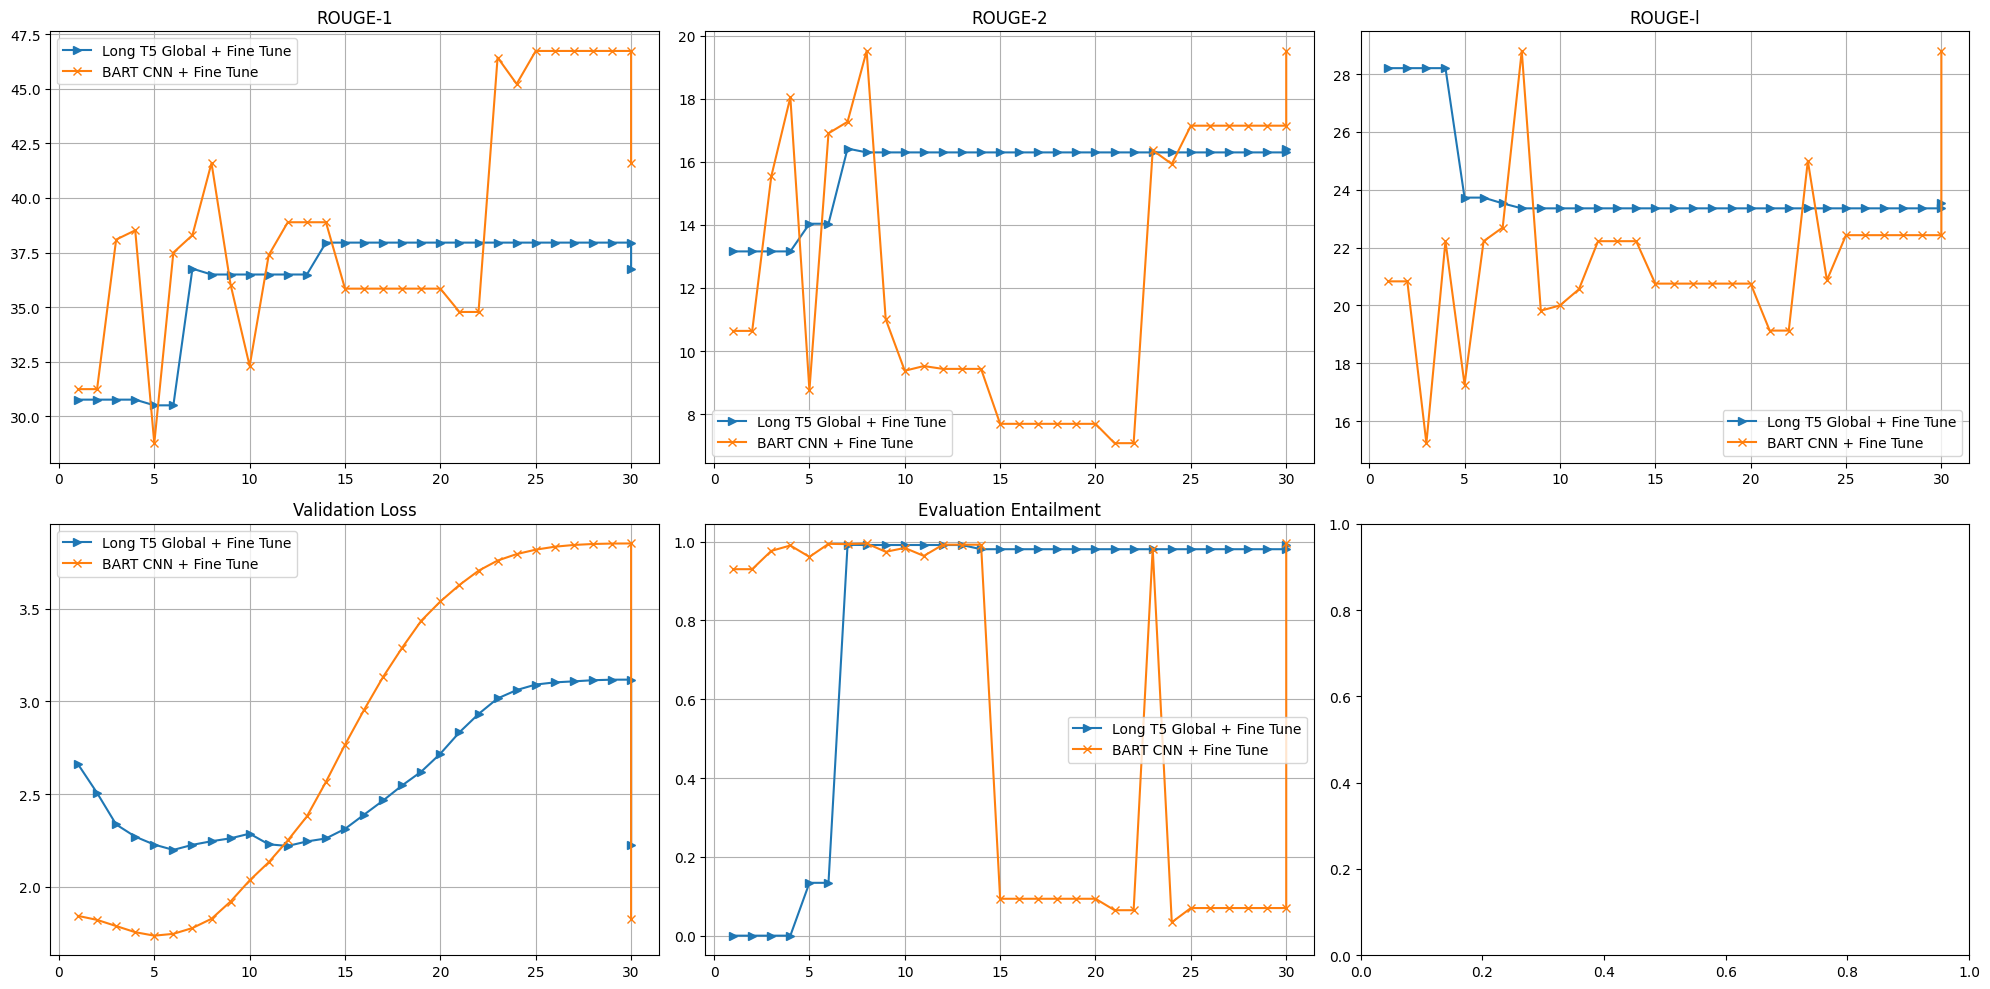

In [193]:
visualize_history(metric_for_visualization)

In [80]:
valid_ds['summary_instruction'][0]

"Summarize based on Reviews: Zenless Zone Zero delivers stylish animations with exceptionally punchy combat impacts that make basic dodge-counters and chain attacks feel incredibly rewarding. The original TV grid navigation mode was painfully slow and broke the momentum of gameplay, though recent patch adjustments made it much more bearable. Character designs and distinct urban aesthetics are bursting with personality, easily standing out among modern action-oriented anime titles. The hip-hop and electronic background music provides energetic rhythm that matches the frenetic tempo of Hollow combat encounters flawlessly. Hollow Zero rogue-lite mode progression becomes repetitive and tedious once weekly point quotas are cleared, offering little build diversity. English voice acting and facial sync in cinematic dialogue sequences are remarkably expressive, conveying genuine charm across the main sibling duo.; Aspects: {'aspect': 'combat impacts', 'opinion': 'exceptionally punchy', 'sentim

In [70]:
valid_ds['target'][0]

'Zenless Zone Zero boasts stylish animations, energetic background music, and engaging voice acting. The combat is exceptionally punchy but the repetitive progression can be tiresome. The original TV grid navigation mode was slow but is now bearable.'

In [69]:
output = trainer_FLAN.model.generate(**FLAN_tokenizer(valid_ds['summary_instruction'][0], return_tensors='pt', max_length=150).to(device))

print(FLAN_tokenizer.decode(output[0], skip_special_tokens=True))

Hollow Zero rogue-lite mode progression becomes repetitive and tedious once weekly point quota


In [144]:
output = trainer_BART_CNN.model.generate(**BART_tokenizer(valid_ds['summary_instruction'][0], return_tensors='pt', max_length=110).to(device))

print(BART_tokenizer.decode(output[0], skip_special_tokens=True))

Zenless Zone Zero delivers stylish animations with exceptionally punchy combat impacts. Original TV grid navigation mode was painfully slow and broke the momentum of gameplay. Character designs and distinct urban aesthetics are bursting with personality. Hip-hop and electronic background music provides energetic rhythm that matches the frenetic tempo of Hollow combat encounters.


### Model Deployment

In [ ]:
!pip -q install pyngrok
!pip -q install python-dotenv
from pyngrok import ngrok
from dotenv import load_dotenv

load_dotenv()
api_key = os.getenv("NGROK_PHASE_3_TOKEN")
ngrok.set_auth_token(api_key)

In [ ]:
deployed_model = trainer_FLAN

In [ ]:
deployed_model

In [ ]:
import threading
import time

from flask import Flask, jsonify, request
from werkzeug.serving import make_server


In [ ]:
# Clear ngrok endpoint usage
ngrok.kill()

In [ ]:
app = Flask(__name__)
port = 5000

public_url = ngrok.connect(port).public_url
app.config["BASE_URL"] = public_url

@app.route("/")
def index():
  return "Hello from Colab phase 3!"

@app.route("/inference", methods=["POST"])
def inference():
  if not request.is_json:
    return jsonify({"msg": "the POST method must be JSON with the body containing 'content'"})
  else:
    content = request.json["content"]
    output = deployed_model.model.generate(**FLAN_tokenizer(content, return_tensors='pt').to(device))
    return jsonify({"msg": FLAN_tokenizer.decode(output[0], skip_special_tokens=True)})

class ThreadingServer(threading.Thread):
  def __init__(self, app, port):
    super().__init__()
    self.server = make_server("127.0.0.1", port, app)

  def run(self):
    print("Starting server")
    self.server.serve_forever()

  def shutdown(self):
    print("Shutting down server")
    self.server.shutdown()


In [ ]:
print(f" * ngrok tunnel \"{public_url}\" -> \"http://127.0.0.1:{port}\"")

In [ ]:
server_thread = ThreadingServer(app, 5000)
server_thread.start() # Create new process in OS level so no blocking

In [ ]:
# Scram button for shutting down the server
server_thread.shutdown()
server_thread.join()